In [ ]:
import os
import glob
import time
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Prevent CuDNN profiling crash by configuring GPU memory growth
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as e:
        print(f"GPU configuration warning: {e}")

# Resolve models directory using dynamic relative paths
CURRENT_DIR = os.getcwd()
POSSIBLE_MODELS_DIRS = [
    os.path.abspath(os.path.join(CURRENT_DIR, "..", "..", "MI BCI", "models")),
    os.path.abspath(os.path.join(CURRENT_DIR, "..", "models")),
    os.path.abspath(os.path.join(CURRENT_DIR, "models"))
]

MODELS_DIR = None
for p in POSSIBLE_MODELS_DIRS:
    if os.path.exists(p) and len(glob.glob(os.path.join(p, "*.h5"))) > 0:
        MODELS_DIR = p
        break

if MODELS_DIR is None:
    raise FileNotFoundError("Could not locate the models directory containing .h5 files!")

print(f"Models directory located at: {MODELS_DIR}")
h5_files = glob.glob(os.path.join(MODELS_DIR, "*.h5"))
print(f"Total model checkpoint files found: {len(h5_files)}")

In [2]:
from tensorflow.keras.layers import Layer, Dense

# ------------------------------------------------------------------------------
# 1. Custom Layers Definitions for ViT-PE and CvT Checkpoint Deserialization
# ------------------------------------------------------------------------------
class Patches(Layer):
    def __init__(self, patch_size, **kwargs):
        super(Patches, self).__init__(**kwargs)
        self.patch_size = patch_size

    def call(self, signals):
        batch_size = tf.shape(signals)[0]
        patches = tf.reshape(
            signals,
            [batch_size, -1, self.patch_size, tf.shape(signals)[-1]]
        )
        return patches

    def get_config(self):
        config = super(Patches, self).get_config()
        config.update({"patch_size": self.patch_size})
        return config


class PatchEncoder(Layer):
    def __init__(self, num_patches, projection_dim, **kwargs):
        super(PatchEncoder, self).__init__(**kwargs)
        self.num_patches = num_patches
        self.projection_dim = projection_dim
        self.projection = Dense(units=projection_dim)
        pos_encoding_matrix = self.get_sinusoidal_position_embedding(
            num_patches, projection_dim
        )
        self.position_embedding = tf.Variable(
            pos_encoding_matrix, trainable=False, name="position_embedding"
        )

    def get_sinusoidal_position_embedding(self, sequence_length, embedding_dim):
        angle_rates = 1.0 / (
            10000 ** (
                tf.range(0, embedding_dim, 2, dtype=tf.float32)
                / float(embedding_dim)
            )
        )
        positions = tf.range(sequence_length, dtype=tf.float32)[:, tf.newaxis]
        angle_rads = positions * angle_rates[tf.newaxis, :]
        sines = tf.math.sin(angle_rads)
        cosines = tf.math.cos(angle_rads)
        pos_encoding = tf.concat([sines, cosines], axis=-1)
        return pos_encoding

    def call(self, patch):
        batch_size = tf.shape(patch)[0]
        patch_height = patch.shape[-2]
        patch_width = patch.shape[-1]
        patch_flattened = tf.reshape(
            patch,
            [batch_size, self.num_patches, patch_height * patch_width]
        )
        encoded = self.projection(patch_flattened)
        encoded += self.position_embedding
        return encoded

    def get_config(self):
        config = super(PatchEncoder, self).get_config()
        config.update({
            "num_patches": self.num_patches,
            "projection_dim": self.projection_dim
        })
        return config


def get_sinusoidal_position_embedding(sequence_length, dim):
    position = np.arange(sequence_length)[:, np.newaxis]
    div_term = np.exp(np.arange(0, dim, 2) * -(np.log(10000.0) / dim))
    pe = np.zeros((sequence_length, dim))
    pe[:, 0::2] = np.sin(position * div_term)
    pe[:, 1::2] = np.cos(position * div_term)
    return tf.constant(pe, dtype=tf.float32)


class SinusoidalPositionEmbedding(Layer):
    def __init__(self, sequence_length, dim, **kwargs):
        super().__init__(**kwargs)
        self.sequence_length = sequence_length
        self.dim = dim
        self.pos_embedding = get_sinusoidal_position_embedding(sequence_length, dim)

    def call(self, x):
        return x + self.pos_embedding

    def get_config(self):
        config = super().get_config()
        config.update({
            "sequence_length": self.sequence_length,
            "dim": self.dim,
        })
        return config


# Dictionary of custom objects for Keras model loading
CUSTOM_OBJECTS = {
    'Patches': Patches,
    'PatchEncoder': PatchEncoder,
    'SinusoidalPositionEmbedding': SinusoidalPositionEmbedding
}

# ------------------------------------------------------------------------------
# 2. Robust Benchmarking Function
# ------------------------------------------------------------------------------
def benchmark_inference(model, input_shape, num_warmup=10, num_repeats=50):
    """
    Measures single-trial inference latency and throughput safely on CPU
    to avoid GPU memory/CuDNN context allocation bottlenecks.
    """
    dummy_input = np.random.randn(1, *input_shape).astype(np.float32)
    dummy_tensor = tf.convert_to_tensor(dummy_input)
    
    with tf.device('/CPU:0'):
        # Warm-up phase
        for _ in range(num_warmup):
            _ = model(dummy_tensor, training=False)
            
        # Benchmark timing
        latencies = []
        for _ in range(num_repeats):
            t0 = time.perf_counter()
            _ = model(dummy_tensor, training=False)
            t1 = time.perf_counter()
            latencies.append((t1 - t0) * 1000.0)
            
    latencies = np.array(latencies)
    mean_lat = np.mean(latencies)
    std_lat = np.std(latencies)
    throughput = 1000.0 / mean_lat
    
    return mean_lat, std_lat, throughput

In [3]:
records = []
ARCHITECTURES = ['eegnet', 'cvt', 'vit_pe']
DATASETS = ['Raw', 'Filtered_8_30Hz', 'Filtered_8_13Hz']

print("Running computational complexity benchmarking...")
print("-" * 80)

for arch in ARCHITECTURES:
    for ds in DATASETS:
        model_filename = f"{arch}_{ds}_fold1.h5"
        model_path = os.path.join(MODELS_DIR, model_filename)
        
        if not os.path.exists(model_path):
            print(f"Warning: {model_filename} not found, skipping.")
            continue
            
        file_size_mb = os.path.getsize(model_path) / (1024 * 1024)
        
        try:
            # Pass custom_objects to successfully load CvT and ViT-PE models
            model = tf.keras.models.load_model(
                model_path,
                custom_objects=CUSTOM_OBJECTS,
                compile=False
            )
        except Exception as e:
            print(f"Error loading {model_filename}: {e}")
            continue
            
        total_params = model.count_params()
        trainable_params = sum([tf.keras.backend.count_params(w) for w in model.trainable_weights])
        input_shape = model.input_shape[1:]
        
        mean_lat, std_lat, throughput = benchmark_inference(model, input_shape)
        
        model_display = arch.upper().replace('_', '-')
        
        records.append({
            'Architecture': model_display,
            'Dataset': ds,
            'Total_Params': total_params,
            'Trainable_Params': trainable_params,
            'Model_Size_MB': round(file_size_mb, 2),
            'Latency_Mean_ms': round(mean_lat, 2),
            'Latency_Std_ms': round(std_lat, 2),
            'Throughput_samples_per_sec': round(throughput, 1),
            'RealTime_Viable (<100ms)': 'Yes' if mean_lat < 100.0 else 'No'
        })
        
        print(f"[{model_display:6s} | {ds:15s}] Params: {total_params:,} | Size: {file_size_mb:.2f} MB | Latency: {mean_lat:.2f} +/- {std_lat:.2f} ms")
        
        tf.keras.backend.clear_session()

complexity_df = pd.DataFrame(records)
complexity_df.to_csv("computational_complexity_summary.csv", index=False)
print("-" * 80)
print("Computational complexity results saved to: computational_complexity_summary.csv")

Running computational complexity benchmarking...
--------------------------------------------------------------------------------
[EEGNET | Raw            ] Params: 45,570 | Size: 0.59 MB | Latency: 14.52 +/- 0.56 ms
[EEGNET | Filtered_8_30Hz] Params: 19,778 | Size: 0.30 MB | Latency: 12.16 +/- 0.68 ms
[EEGNET | Filtered_8_13Hz] Params: 19,778 | Size: 0.30 MB | Latency: 12.14 +/- 0.73 ms
[CVT    | Raw            ] Params: 461,570 | Size: 5.59 MB | Latency: 35.46 +/- 3.09 ms
[CVT    | Filtered_8_30Hz] Params: 461,570 | Size: 5.59 MB | Latency: 38.72 +/- 1.98 ms
[CVT    | Filtered_8_13Hz] Params: 561,154 | Size: 6.79 MB | Latency: 39.88 +/- 5.04 ms
[VIT-PE | Raw            ] Params: 1,784,578 | Size: 20.59 MB | Latency: 15.77 +/- 0.81 ms
[VIT-PE | Filtered_8_30Hz] Params: 1,584,130 | Size: 18.28 MB | Latency: 19.26 +/- 1.10 ms
[VIT-PE | Filtered_8_13Hz] Params: 730,434 | Size: 8.77 MB | Latency: 42.09 +/- 2.30 ms
---------------------------------------------------------------------------

In [4]:
arch_summary = complexity_df.groupby('Architecture').agg({
    'Total_Params': 'first',
    'Trainable_Params': 'first',
    'Model_Size_MB': 'mean',
    'Latency_Mean_ms': 'mean',
    'Throughput_samples_per_sec': 'mean'
}).reset_index()

arch_summary.rename(columns={
    'Total_Params': 'Total Parameters',
    'Trainable_Params': 'Trainable Parameters',
    'Model_Size_MB': 'Disk Size (MB)',
    'Latency_Mean_ms': 'Inference Latency (ms)',
    'Throughput_samples_per_sec': 'Throughput (samples/s)'
}, inplace=True)

print("\n" + "="*85)
print("🎯 COMPUTATIONAL COMPLEXITY TABLE FOR REVIEWER RESPONSE")
print("="*85)
print(arch_summary.to_markdown(index=False))


🎯 COMPUTATIONAL COMPLEXITY TABLE FOR REVIEWER RESPONSE
| Architecture   |   Total Parameters |   Trainable Parameters |   Disk Size (MB) |   Inference Latency (ms) |   Throughput (samples/s) |
|:---------------|-------------------:|-----------------------:|-----------------:|-------------------------:|-------------------------:|
| CVT            |             461570 |                 461570 |         5.99     |                  38.02   |                  26.3667 |
| EEGNET         |              45570 |                  44994 |         0.396667 |                  12.94   |                  77.8333 |
| VIT-PE         |            1784578 |                1783554 |        15.88     |                  25.7067 |                  46.3667 |


Saved figures to computational_complexity_comparison.png & .pdf


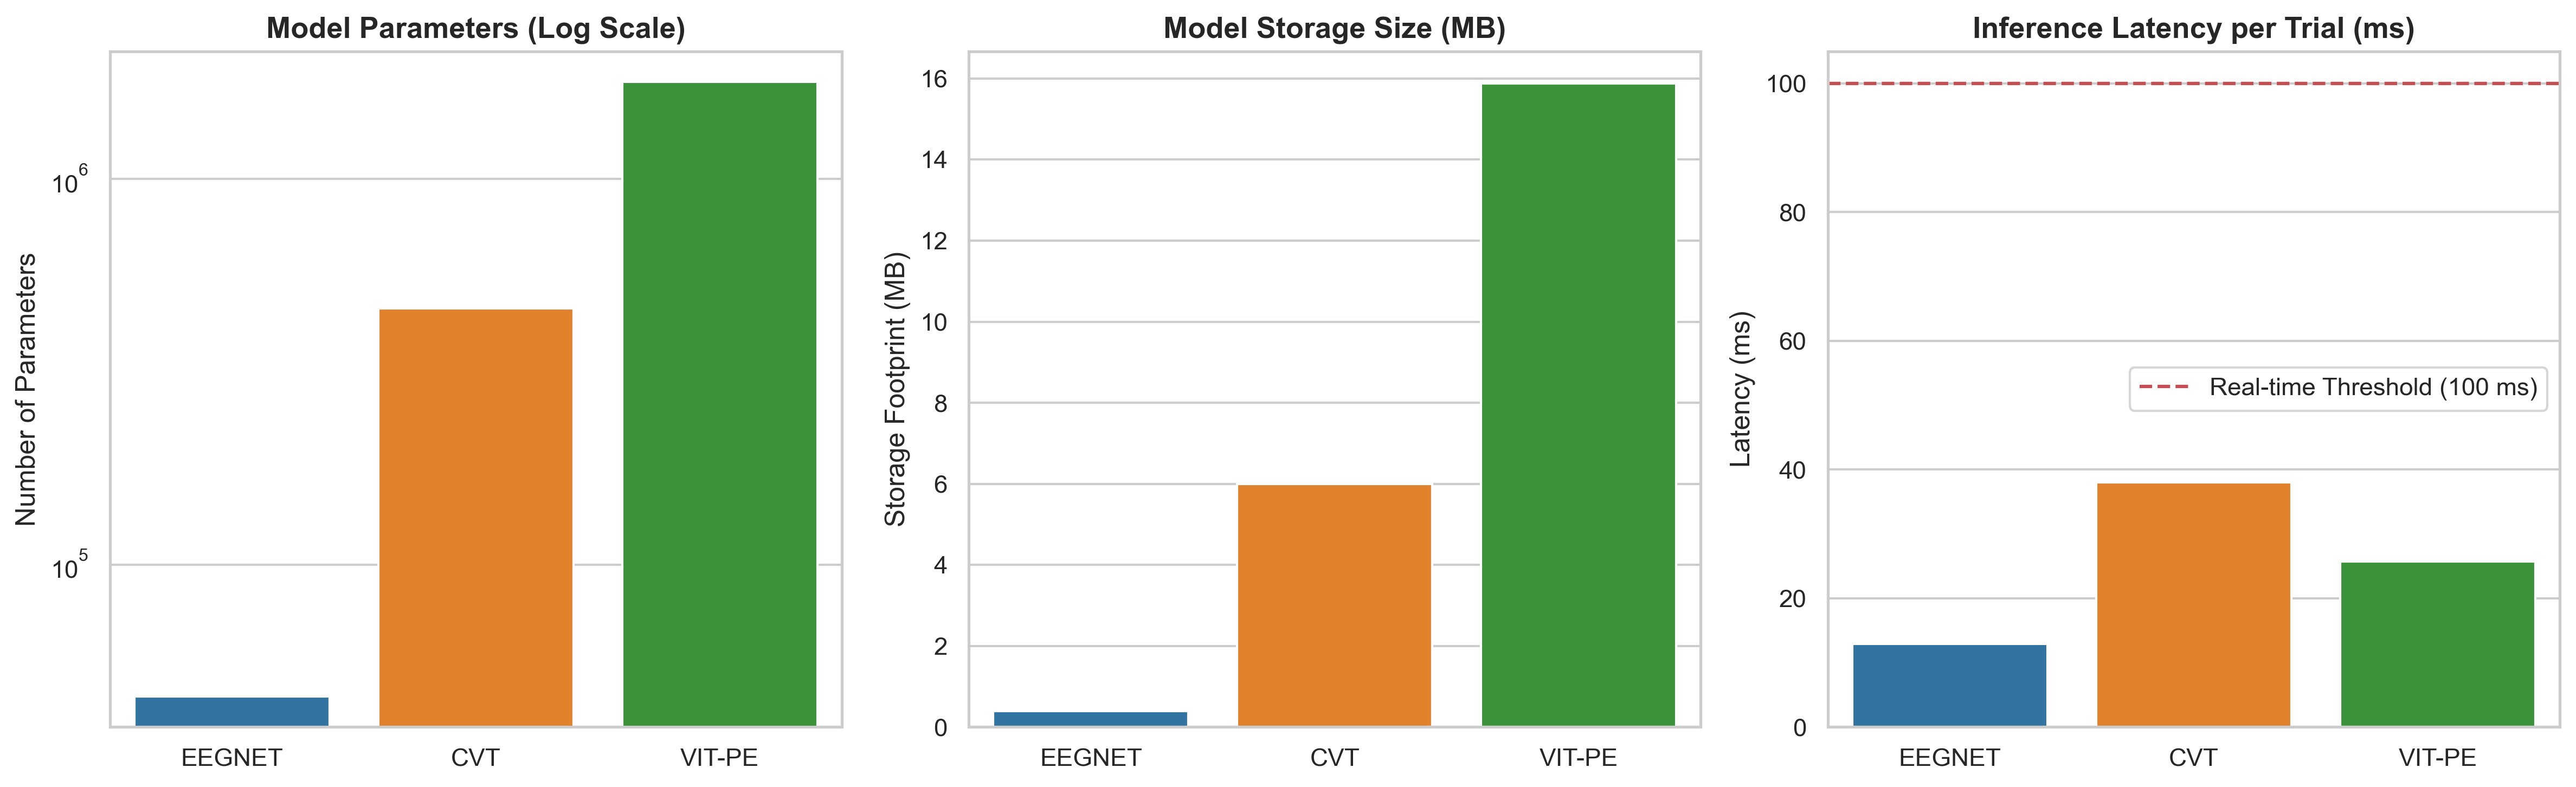

In [5]:
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 3, figsize=(16, 5), dpi=300)

models_order = ['EEGNET', 'CVT', 'VIT-PE']
colors = {'EEGNET': '#1f77b4', 'CVT': '#ff7f0e', 'VIT-PE': '#2ca02c'}

# 1. Total Parameters Plot
sns.barplot(data=arch_summary, x='Architecture', y='Total Parameters', ax=axes[0], palette=colors, hue='Architecture', legend=False, order=models_order)
axes[0].set_title("Model Parameters (Log Scale)", fontsize=13, fontweight='bold')
axes[0].set_yscale('log')
axes[0].set_ylabel("Number of Parameters")
axes[0].set_xlabel("")

# 2. Model Size Plot
sns.barplot(data=arch_summary, x='Architecture', y='Disk Size (MB)', ax=axes[1], palette=colors, hue='Architecture', legend=False, order=models_order)
axes[1].set_title("Model Storage Size (MB)", fontsize=13, fontweight='bold')
axes[1].set_ylabel("Storage Footprint (MB)")
axes[1].set_xlabel("")

# 3. Inference Latency Plot
sns.barplot(data=arch_summary, x='Architecture', y='Inference Latency (ms)', ax=axes[2], palette=colors, hue='Architecture', legend=False, order=models_order)
axes[2].axhline(y=100, color='r', linestyle='--', label='Real-time Threshold (100 ms)')
axes[2].set_title("Inference Latency per Trial (ms)", fontsize=13, fontweight='bold')
axes[2].set_ylabel("Latency (ms)")
axes[2].set_xlabel("")
axes[2].legend()

plt.tight_layout()
plt.savefig("computational_complexity_comparison.png", dpi=300)
plt.savefig("computational_complexity_comparison.pdf")
print("Saved figures to computational_complexity_comparison.png & .pdf")
plt.show()